In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, random
import tensorflow as tf
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('delhi_daily_master.csv', parse_dates=['date'])
print(df.shape)
print(df.date.min(), df.date.max())
print(df.isna().sum()[df.isna().sum() > 0])

(700, 34)
2023-01-01 00:00:00 2024-11-30 00:00:00
pm2_5_lag1              1
pm2_5_lag2              2
pm2_5_lag7              7
pm2_5_roll7             6
temp_roll3              2
target_next_day_pm25    1
dtype: int64


In [2]:
FEATURES = ['pm2_5','pm10','no2','co','so2','o3','dust_log',
            'temp','humidity','windspeed','precip','pressure',
            'demand_mean','demand_peak',
            'is_weekend','is_holiday','month_sin','month_cos']

d = df.dropna(subset=FEATURES + ['target_next_day_pm25']).reset_index(drop=True)
print(len(d))

699


In [3]:
# After basic cleaning, chronological split and scaling
n = len(d)
d1, d2 = int(0.70*n), int(0.85*n)
train = d.loc[:d1-1, FEATURES]
mn, mx = train.min(), train.max()
scaled = ((d[FEATURES] - mn) / (mx - mn).replace(0, 1)).to_numpy('float32')
target = d['target_next_day_pm25'].to_numpy('float32')

In [5]:
# We are using seven day windows
WINDOW = 7
X, y, t = [], [], []
for i in range(n - WINDOW + 1):
    end = i + WINDOW - 1
    X.append(scaled[i:i+WINDOW]); y.append(target[end]); t.append(end + 1)
X, y, t = np.array(X), np.array(y), np.array(t)

tr, va, te = t < d1, (t >= d1) & (t < d2), t >= d2
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
print(Xtr.shape, Xva.shape, Xte.shape)

(482, 7, 18) (105, 7, 18) (106, 7, 18)


In [6]:
pm_i = FEATURES.index('pm2_5')
today = lambda X_: X_[:, -1, pm_i] * (mx['pm2_5'] - mn['pm2_5']) + mn['pm2_5']
btr, bva, bte = today(Xtr), today(Xva), today(Xte)   # today's PM2.5 (µg/m³)

dtr, dva = ytr - btr, yva - bva                       # what the model predicts
mu, sd = dtr.mean(), dtr.std()
z = lambda v: (v - mu) / sd

def metrics(yt, yp):
    return dict(RMSE=np.sqrt(mean_squared_error(yt, yp)),
                MAE=mean_absolute_error(yt, yp), R2=r2_score(yt, yp))

In [7]:
# Baselines from Random Forest
flat = lambda A: A.reshape(len(A), -1)
res = {}
res['Persistence'] = metrics(yte, bte)

ridge = Ridge(alpha=100).fit(flat(Xtr), dtr)
res['Ridge'] = metrics(yte, bte + ridge.predict(flat(Xte)))

rf = RandomForestRegressor(300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(flat(Xtr), dtr)
res['Random Forest'] = metrics(yte, bte + rf.predict(flat(Xte)))
pd.DataFrame(res).T.round(3)

,RMSE,MAE,R2
Persistence,17.937,12.950,0.760
Ridge,17.433,12.568,0.774
Random Forest,17.185,12.506,0.780


In [12]:
from tqdm.auto import tqdm
from tqdm.keras import TqdmCallback
def fit_lstm(Xa, da, Xb, db, seed, show_epochs=False):
    tf.keras.utils.set_random_seed(seed)
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=Xa.shape[1:]),
        tf.keras.layers.LSTM(32, kernel_regularizer=tf.keras.regularizers.l2(1e-3)),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')

    callbacks = [
        tf.keras.callbacks.EarlyStopping(patience=12, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)]
    if show_epochs:
        callbacks.append(TqdmCallback(verbose=0, leave=False))   # per-epoch bar

    h = m.fit(Xa, z(da), validation_data=(Xb, z(db)), epochs=150, batch_size=32,
              shuffle=False, verbose=0, callbacks=callbacks)
    return m, h

preds = []
for s in tqdm(range(5), desc='LSTM seeds'):
    m, h = fit_lstm(Xtr, dtr, Xva, dva, 42 + s)
    preds.append(bte + m.predict(Xte, verbose=0).ravel() * sd + mu)
    if s == 0: hist = h
lstm_pred = np.mean(preds, axis=0)
res['LSTM'] = metrics(yte, lstm_pred)
pd.DataFrame(res).T.round(3)

LSTM seeds:   0%|          | 0/5 [00:00<?, ?it/s]

,RMSE,MAE,R2
Persistence,17.937,12.950,0.760
Ridge,17.433,12.568,0.774
Random Forest,17.185,12.506,0.780
LSTM,17.659,12.762,0.768


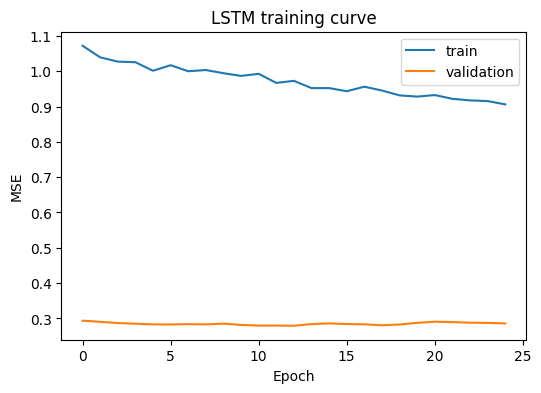

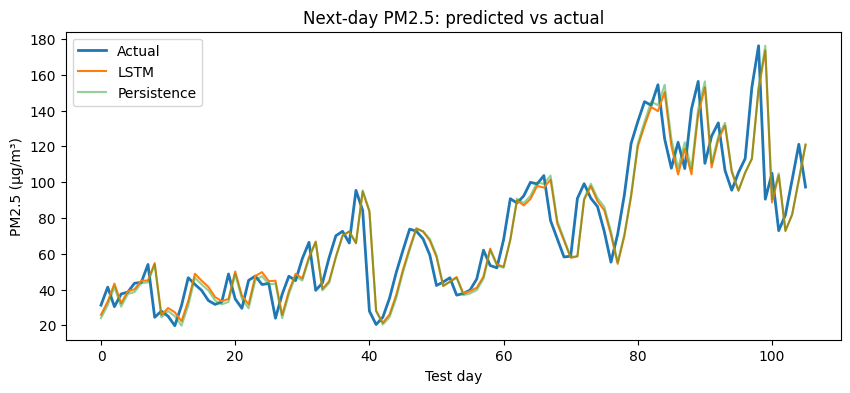

In [13]:
plt.figure(figsize=(6,4))
plt.plot(hist.history['loss'], label='train'); plt.plot(hist.history['val_loss'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('LSTM training curve'); plt.legend()
plt.savefig('loss_curve.png', dpi=200, bbox_inches='tight'); plt.show()

plt.figure(figsize=(10,4))
plt.plot(yte, label='Actual', lw=2); plt.plot(lstm_pred, label='LSTM')
plt.plot(bte, label='Persistence', alpha=.5)
plt.xlabel('Test day'); plt.ylabel('PM2.5 (µg/m³)'); plt.legend()
plt.title('Next-day PM2.5: predicted vs actual')
plt.savefig('predicted_vs_actual.png', dpi=200, bbox_inches='tight'); plt.show()

In [14]:
groups = {'All features': [],
          'Without weather': ['temp','humidity','windspeed','precip','pressure'],
          'Without energy': ['demand_mean','demand_peak'],
          'Without other pollutants': ['pm10','no2','co','so2','o3','dust_log'],
          'PM2.5 history only': [f for f in FEATURES if f != 'pm2_5']}
abl = {}
for name, drop in groups.items():
    keep = [k for k, f in enumerate(FEATURES) if f not in drop]
    p = []
    for s in range(3):
        m, _ = fit_lstm(Xtr[:,:,keep], dtr, Xva[:,:,keep], dva, 42 + s)
        p.append(bte + m.predict(Xte[:,:,keep], verbose=0).ravel() * sd + mu)
    abl[name] = metrics(yte, np.mean(p, axis=0))
pd.DataFrame(abl).T.round(3)

,RMSE,MAE,R2
All features,17.659,12.749,0.768
Without weather,17.634,12.743,0.768
Without energy,17.549,12.679,0.771
Without other pollutants,17.388,12.755,0.775
PM2.5 history only,16.873,12.422,0.788
